In [15]:
from Bio import SeqIO
import pandas as pd
from pycirclize import Circos
from Bio.SeqFeature import SeqFeature

In [16]:
def get_proteins(gbk_file, bait):
    data = []
    for record in SeqIO.parse(gbk_file, "genbank"):
        for feature in record.features:
            data.append({
                'seqid': record.id,
                'locus': feature.qualifiers.get(bait, [''])[0],
                'type': feature.type,
                'start': feature.location.start,
                'end': feature.location.end,
                'strand': feature.location.strand            
                })
    data = pd.DataFrame(data)
    data = data.loc[data.type != "source"]
    return data

In [17]:
illumina_path = "../prokka/ilumina/PROKKA_11092023/PROKKA_11092023.gbk"
illumina_proteins = get_proteins(illumina_path,"locus_tag")
illumina_proteins

,seqid,locus,type,start,end,strand
1,Scaffold_1,OPPBIMDH_00001,CDS,171,1665,-1
2,Scaffold_1,OPPBIMDH_00002,CDS,1938,3603,1
3,Scaffold_1,OPPBIMDH_00003,CDS,3990,5196,1
4,Scaffold_1,OPPBIMDH_00004,CDS,5312,5738,-1
5,Scaffold_1,OPPBIMDH_00005,CDS,5753,6785,-1
...,...,...,...,...,...,...
6193,Scaffold_9,OPPBIMDH_06151,CDS,132,3090,1
6194,Scaffold_9,OPPBIMDH_06152,CDS,2941,4144,-1
6196,Scaffold_10,OPPBIMDH_06153,CDS,262,886,1
6197,Scaffold_10,OPPBIMDH_06154,CDS,978,1191,1


In [18]:
illumina_antismash_path = "../BGC/illumina/illumina-bgcs.gbk"
illumina_BGC = get_proteins(illumina_antismash_path,"locus_tag")
illumina_BGC = illumina_BGC.loc[illumina_BGC.type == "CDS"]
illumina_BGC = illumina_proteins.loc[illumina_proteins.locus.isin(illumina_BGC.locus.to_list())]
illumina_BGC

,seqid,locus,type,start,end,strand
166,Scaffold_1,OPPBIMDH_00165,CDS,173652,175806,-1
167,Scaffold_1,OPPBIMDH_00166,CDS,175802,176483,-1
168,Scaffold_1,OPPBIMDH_00167,CDS,176479,177004,-1
169,Scaffold_1,OPPBIMDH_00168,CDS,177090,177939,1
170,Scaffold_1,OPPBIMDH_00169,CDS,177935,178781,1
...,...,...,...,...,...,...
6181,Scaffold_6,OPPBIMDH_06142,CDS,24423,25185,-1
6182,Scaffold_6,OPPBIMDH_06143,CDS,25473,31035,1
6183,Scaffold_6,OPPBIMDH_06144,CDS,31243,33547,1
6184,Scaffold_6,OPPBIMDH_06145,CDS,33793,35659,-1


In [19]:
ring_coord = (50,55)

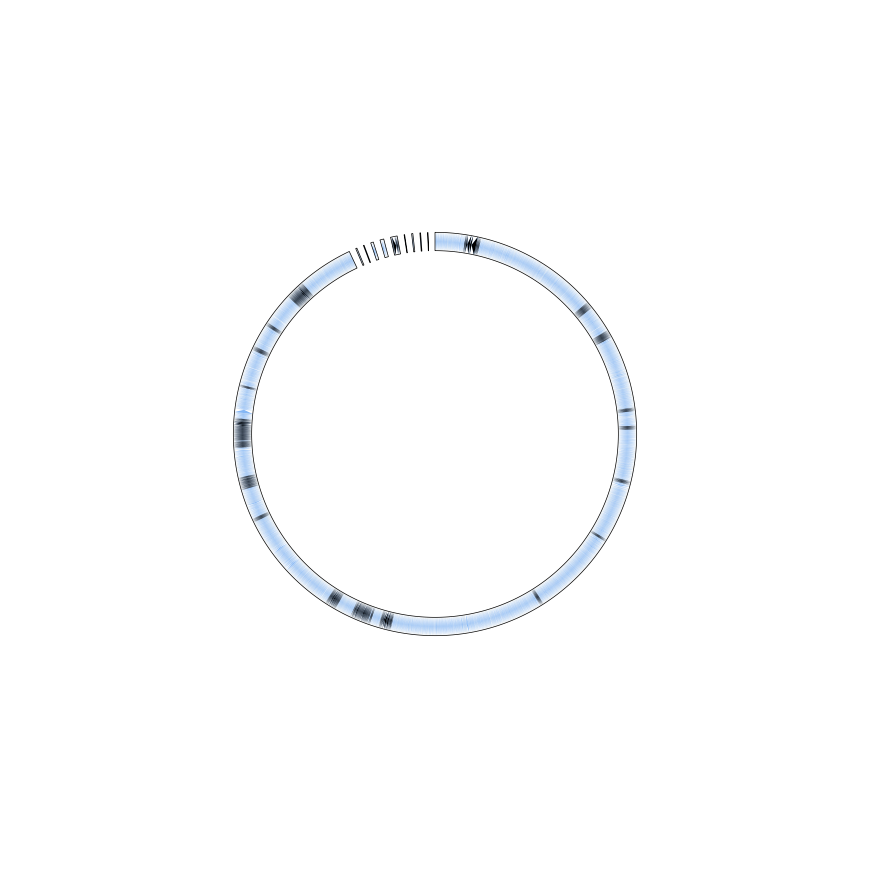

In [20]:
sectors = {record.id:len(record.seq) for record in SeqIO.parse("../prokka/ilumina/PROKKA_11092023/PROKKA_11092023.fna","fasta")}
circos = Circos(sectors,space = 2)


for sector in circos.sectors:
    #Out
    out_track = sector.add_track((ring_coord[0], ring_coord[1]))
    out_track.axis(fc="white", ec="black")

    #Original CDS
    df = illumina_proteins[illumina_proteins.seqid == sector.name]
    for i in df.itertuples():
        cds_ = sector.add_track((ring_coord[0], ring_coord[1]))
        match i.strand:
            case 1:
                cds_.arrow(start = i.start, end = i.end, color = "#84b6f4")
            case -1:
                cds_.arrow(end = i.start, start= i.end, color = "#84b6f4")
    
    #BGCs
    df = illumina_BGC[illumina_BGC.seqid == sector.name]
    for i in df.itertuples():
        cds_ = sector.add_track((ring_coord[0], ring_coord[1]))
        match i.strand:
            case 1:
                cds_.arrow(
                    start = i.start, 
                    end =   i.end, 
                    color = "black")
            case -1:
                cds_.arrow(
                    end =   i.start, 
                    start = i.end, 
                    color = "black")



fig = circos.plotfig()
fig.savefig("Ring0.svg")


In [21]:
minion_path = "../prokka/minion/PROKKA_11092023/PROKKA_11092023.gbk"
minion_proteins = get_proteins(minion_path,"locus_tag")

In [22]:
minion_antismash_path = "../BGC/minion/minion-bgcs.gbk"
minion_BGC = get_proteins(minion_antismash_path,"locus_tag")
minion_BGC = minion_BGC.loc[minion_BGC.type == "CDS"]
minion_BGC = minion_proteins.loc[minion_proteins.locus.isin(minion_BGC.locus.to_list())]
minion_BGC

,seqid,locus,type,start,end,strand
228,contig_2,ONHDLDEL_00227,CDS,137277,137382,-1
229,contig_2,ONHDLDEL_00228,CDS,137330,137666,-1
230,contig_2,ONHDLDEL_00229,CDS,138751,139609,1
231,contig_2,ONHDLDEL_00230,CDS,139661,140084,1
232,contig_2,ONHDLDEL_00231,CDS,140071,140644,1
...,...,...,...,...,...,...
11107,contig_3,ONHDLDEL_11105,CDS,1868474,1868942,1
11108,contig_3,ONHDLDEL_11106,CDS,1868917,1869238,-1
11109,contig_3,ONHDLDEL_11107,CDS,1869267,1869390,-1
11110,contig_3,ONHDLDEL_11108,CDS,1869338,1869797,-1


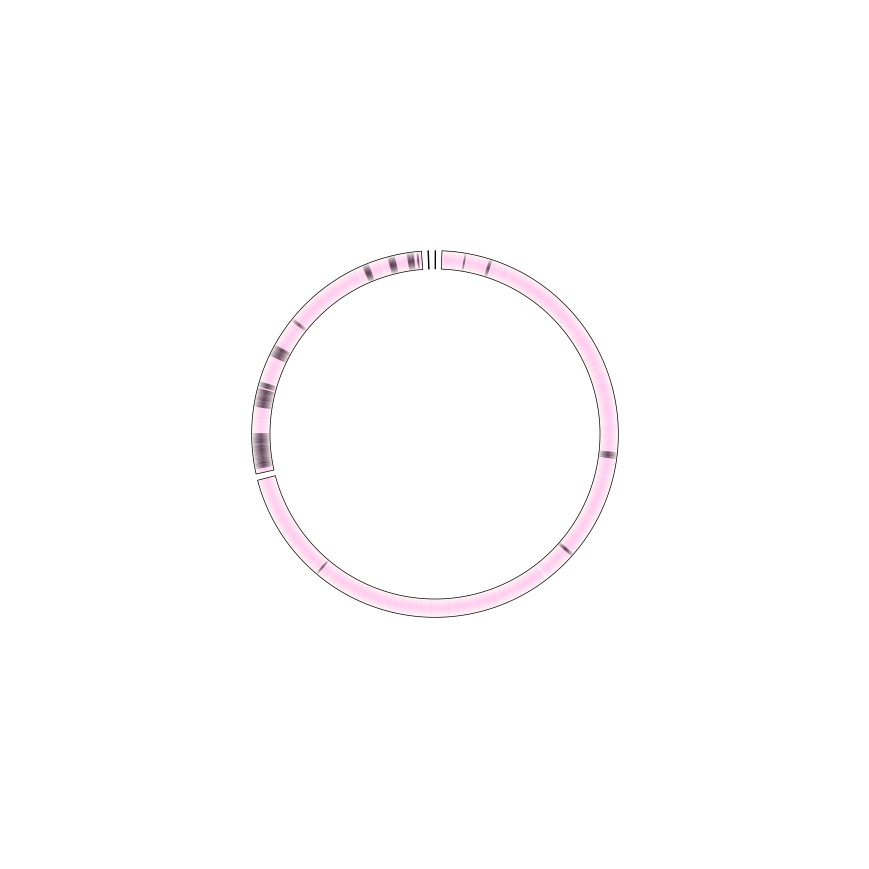

In [24]:
sectors = {record.id:len(record.seq) for record in SeqIO.parse("../prokka/minion/PROKKA_11092023/PROKKA_11092023.fna","fasta")}
circos = Circos(sectors,space = 2)



for sector in circos.sectors:
    #Out
    out_track = sector.add_track((ring_coord[0], ring_coord[1]))
    out_track.axis(fc="white", ec="black")

    #Original CDS
    df = minion_proteins[minion_proteins.seqid == sector.name]
    for i in df.itertuples():
        cds_ = sector.add_track((ring_coord[0], ring_coord[1]))
        match i.strand:
            case 1:
                cds_.arrow(start = i.start, end = i.end, color = "#ffb0ef")
            case -1:
                cds_.arrow(end = i.start, start= i.end, color = "#ffb0ef")

    #BGCs
    df = minion_BGC[minion_BGC.seqid == sector.name]
    for i in df.itertuples():
        cds_ = sector.add_track((ring_coord[0], ring_coord[1]))
        match i.strand:
            case 1:
                cds_.arrow(
                    start = i.start, 
                    end =   i.end, 
                    color = "black")
            case -1:
                cds_.arrow(
                    end =   i.start, 
                    start = i.end, 
                    color = "black")




fig = circos.plotfig()
fig.savefig("Ring1.svg")

In [25]:
minion_new_path = "../prokka/minion_new/PROKKA_09042024/PROKKA_09042024.gbk"
minion_new_proteins = get_proteins(minion_new_path,"locus_tag")
minion_new_proteins

,seqid,locus,type,start,end,strand
1,contig_1,FIGOLEGC_00001,CDS,151,817,1
2,contig_1,FIGOLEGC_00002,CDS,899,1079,1
3,contig_1,FIGOLEGC_00003,CDS,1028,1973,-1
4,contig_1,FIGOLEGC_00004,CDS,2592,3417,-1
5,contig_1,FIGOLEGC_00005,CDS,3370,4060,-1
...,...,...,...,...,...,...
6548,contig_1,FIGOLEGC_06548,CDS,6784807,6785356,-1
6550,contig_2,FIGOLEGC_06549,CDS,147,609,-1
6551,contig_2,FIGOLEGC_06550,CDS,605,2240,-1
6553,contig_3,FIGOLEGC_06551,CDS,604,1633,-1


In [26]:
minion_new_antismash_path = "../BGC/minion_new/minion-new-bgcs.gbk"
minion_new_BGC = get_proteins(minion_new_antismash_path,"locus_tag")
minion_new_BGC = minion_new_BGC.loc[minion_new_BGC.type == "CDS"]
minion_new_BGC = minion_new_proteins.loc[minion_new_proteins.locus.isin(minion_new_BGC.locus.to_list())]
minion_new_BGC

,seqid,locus,type,start,end,strand
635,contig_1,FIGOLEGC_00635,CDS,646778,647315,1
636,contig_1,FIGOLEGC_00636,CDS,647314,649717,1
637,contig_1,FIGOLEGC_00637,CDS,649713,651129,1
638,contig_1,FIGOLEGC_00638,CDS,651125,652271,1
639,contig_1,FIGOLEGC_00639,CDS,652257,652512,1
...,...,...,...,...,...,...
6533,contig_1,FIGOLEGC_06533,CDS,6768614,6769040,-1
6534,contig_1,FIGOLEGC_06534,CDS,6769317,6769887,1
6535,contig_1,FIGOLEGC_06535,CDS,6769888,6770482,1
6537,contig_1,FIGOLEGC_06537,CDS,6771179,6771581,-1


In [27]:
ring_coord = (40,45)

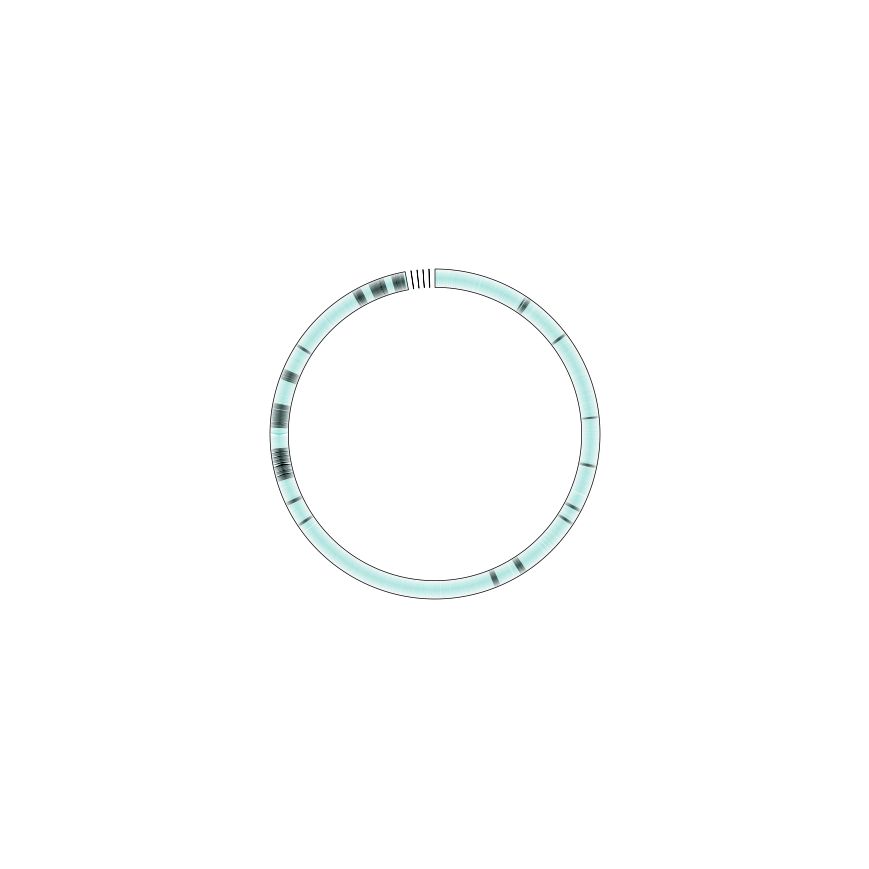

In [28]:
sectors = {record.id:len(record.seq) for record in SeqIO.parse("../prokka/minion_new/PROKKA_09042024/PROKKA_09042024.fna","fasta")}
circos = Circos(sectors,space = 2)
for sector in circos.sectors:
    #Out
    out_track = sector.add_track((ring_coord[0], ring_coord[1]))
    out_track.axis(fc="white", ec="black")

    #Original CDS
    df = minion_new_proteins[minion_new_proteins.seqid == sector.name]
    for i in df.itertuples():
        cds_ = sector.add_track((ring_coord[0], ring_coord[1]))
        match i.strand:
            case 1:
                cds_.arrow(start = i.start, end = i.end, color = "#88DBD3")
            case -1:
                cds_.arrow(end = i.start, start= i.end, color = "#88DBD3")

    #BGCs
    df = minion_new_BGC[minion_new_BGC.seqid == sector.name]
    for i in df.itertuples():
        cds_ = sector.add_track((ring_coord[0], ring_coord[1]))
        match i.strand:
            case 1:
                cds_.arrow(
                    start = i.start, 
                    end =   i.end, 
                    color = "black")
            case -1:
                cds_.arrow(
                    end =   i.start, 
                    start = i.end, 
                    color = "black")


fig = circos.plotfig()
fig.savefig("Ring2.svg")